### This sandbox is to generate some interferograms 'out of the box'. 

In [2]:
# Running the quickstart after installation.

In [1]:
!pip install eq-insar[viz]

In [10]:
from eq_insar import generate_synthetic_insar, plot_insar_products

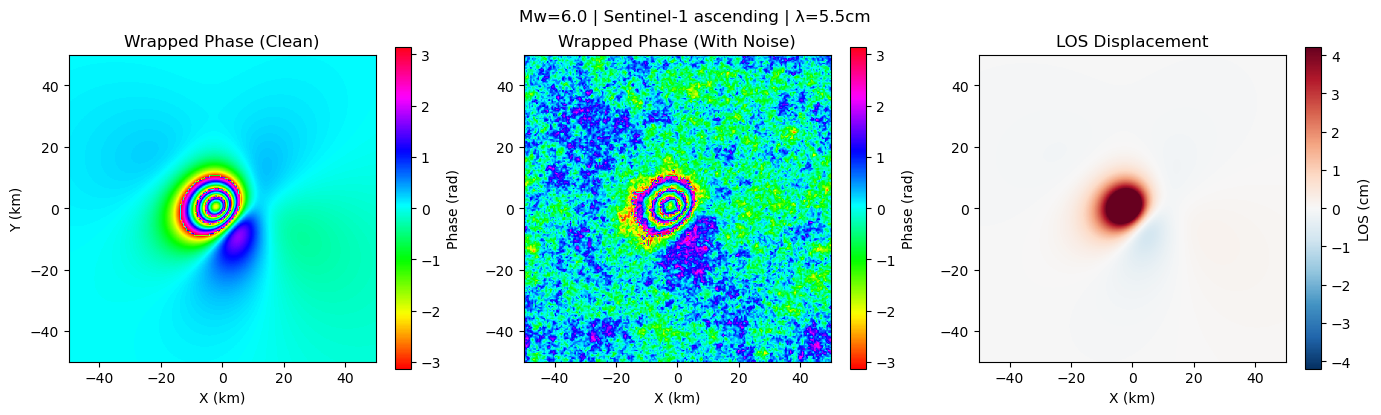

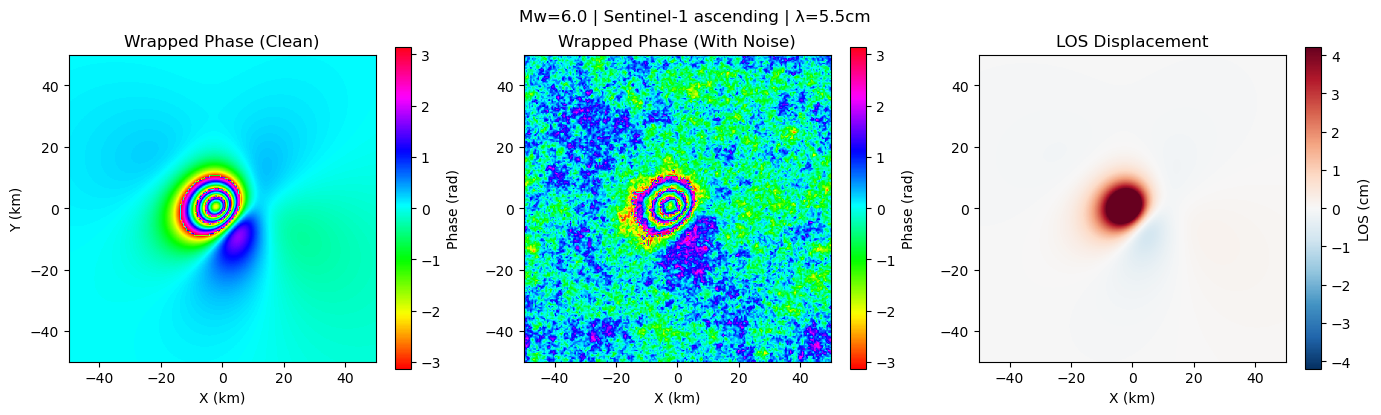

In [5]:
# Mw 6.0 thrust earthquake — Sentinel-1 ascending
result = generate_synthetic_insar(
    Mw=6.0, strike_deg=45, dip_deg=30, rake_deg=90,
    depth_km=10, satellite='sentinel1'
)

plot_insar_products(result)  # wrapped phase, unwrapped, LOS

In [7]:
result

{'X_km': array([[-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ],
        [-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ],
        [-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ],
        ...,
        [-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ],
        [-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ],
        [-50. , -49.5, -49. , ...,  49. ,  49.5,  50. ]]),
 'Y_km': array([[-50. , -50. , -50. , ..., -50. , -50. , -50. ],
        [-49.5, -49.5, -49.5, ..., -49.5, -49.5, -49.5],
        [-49. , -49. , -49. , ..., -49. , -49. , -49. ],
        ...,
        [ 49. ,  49. ,  49. , ...,  49. ,  49. ,  49. ],
        [ 49.5,  49.5,  49.5, ...,  49.5,  49.5,  49.5],
        [ 50. ,  50. ,  50. , ...,  50. ,  50. ,  50. ]]),
 'Ue': array([[-6.91249212e-05, -7.04252252e-05, -7.17007044e-05, ...,
         -1.19757857e-03, -1.18998968e-03, -1.18230293e-03],
        [-6.99788110e-05, -7.13382860e-05, -7.26732214e-05, ...,
         -1.21481685e-03, -1.20690472e-03, -1.19889783e-03],
        [-7.

In [2]:
# Other important imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

In [3]:
# Get all the packages 
from eq_insar import (
    generate_synthetic_insar,
    generate_timeseries,
    generate_training_batch,
    list_satellites,
    get_satellite,
    plot_displacement_components,
    plot_insar_products,
    plot_timeseries_frames,
)

# Plot style
plt.style.use('default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

In [13]:
# Generate synthetic interferogram
result = generate_synthetic_insar(
    Mw=6.0,                    # Moment magnitude
    strike_deg=30,             # Fault strike (clockwise from N)
    dip_deg=45,                # Fault dip angle
    rake_deg=90,               # Thrust fault
    depth_km=10,               # Source depth
    satellite='sentinel1',     # Sentinel-1 geometry
    orbit='ascending',         # Ascending orbit
    add_noise=True,            # Include noise
    seed=42                    # Reproducibility
)

print(f"Generated interferogram: {result['los_displacement'].shape}")
print(f"Max LOS displacement: {np.abs(result['los_displacement']).max()*100:.1f} cm")

Generated interferogram: (201, 201)
Max LOS displacement: 9.4 cm


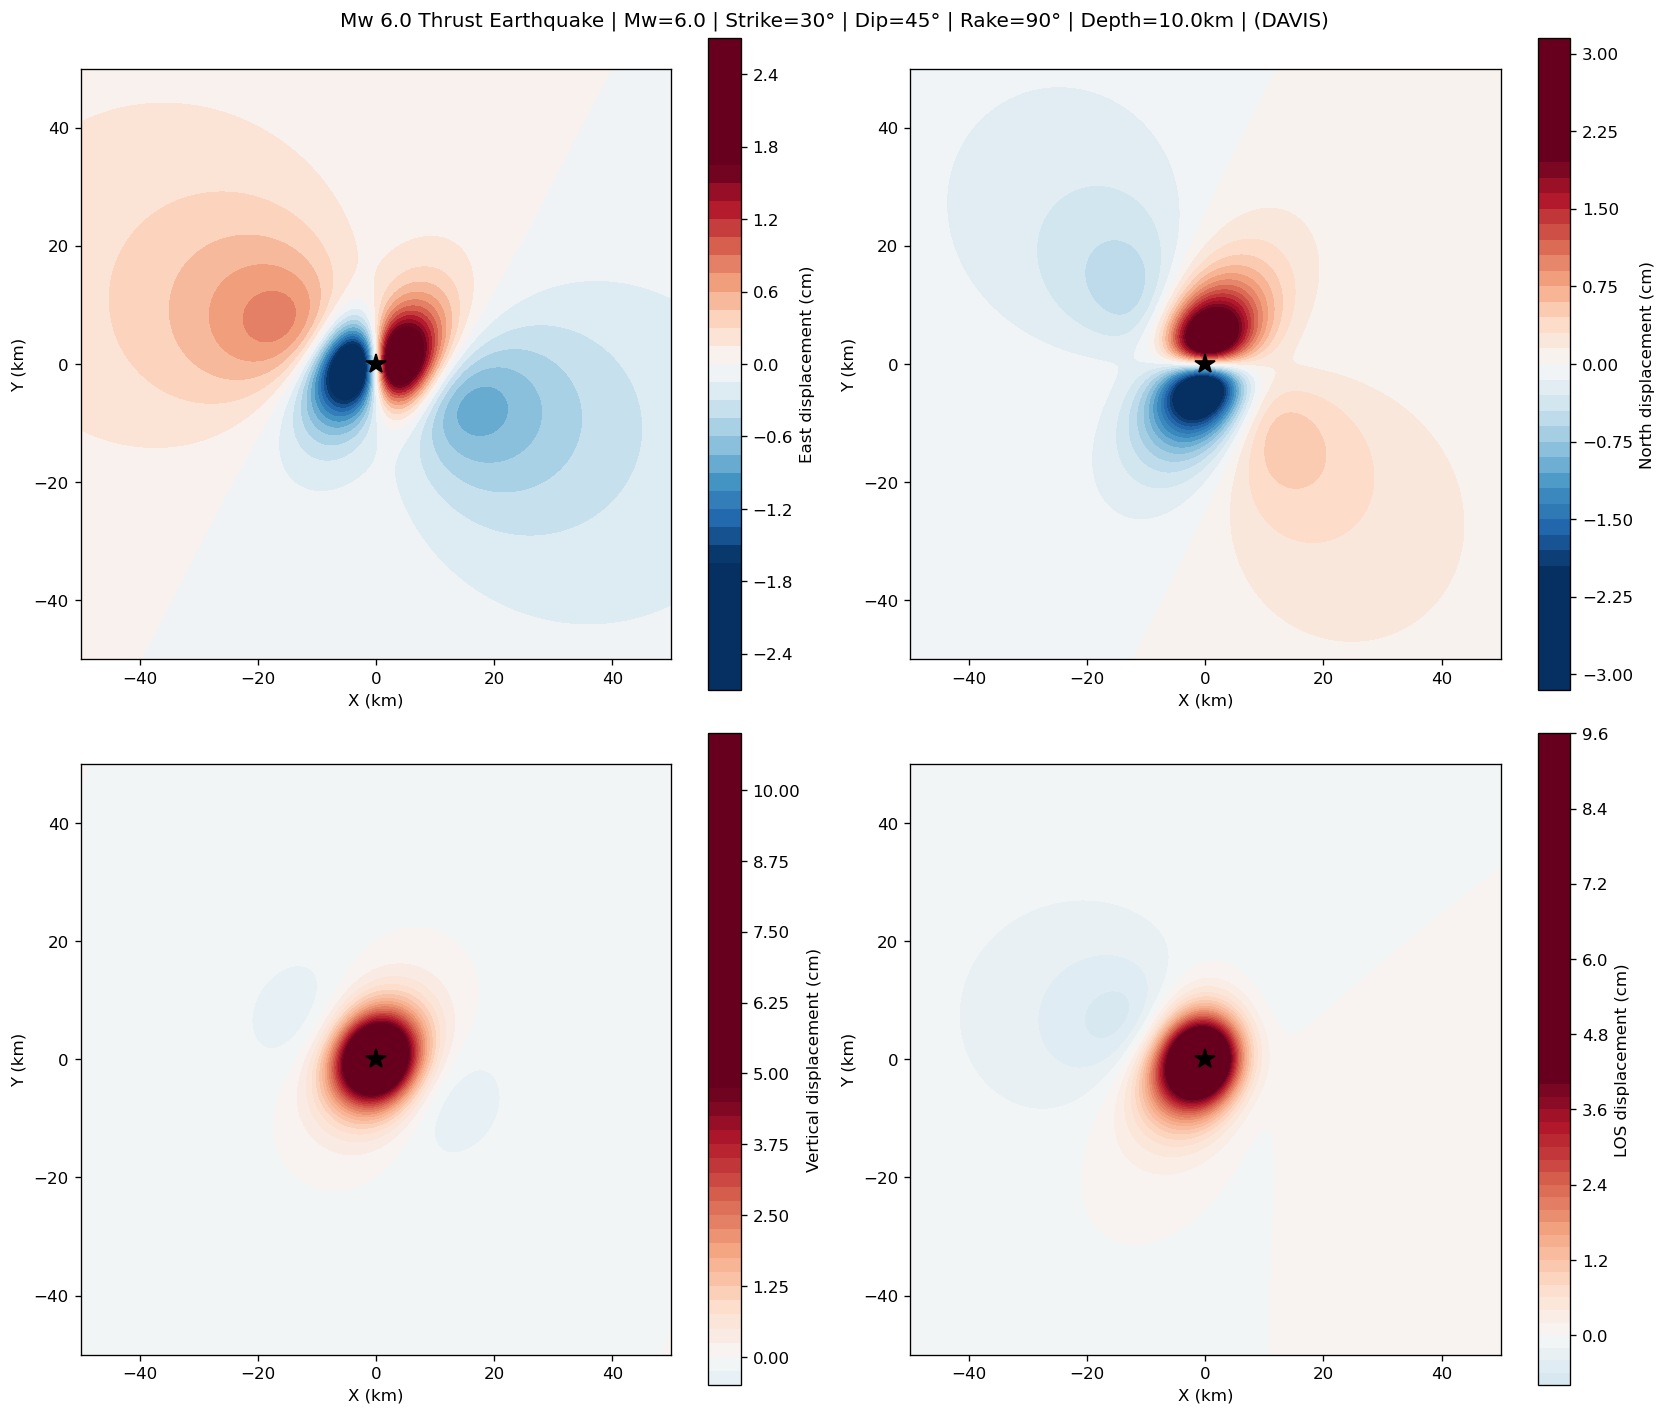

In [14]:
# Visualize displacement components
fig = plot_displacement_components(result, title_prefix="Mw 6.0 Thrust Earthquake")
plt.tight_layout()
plt.show()

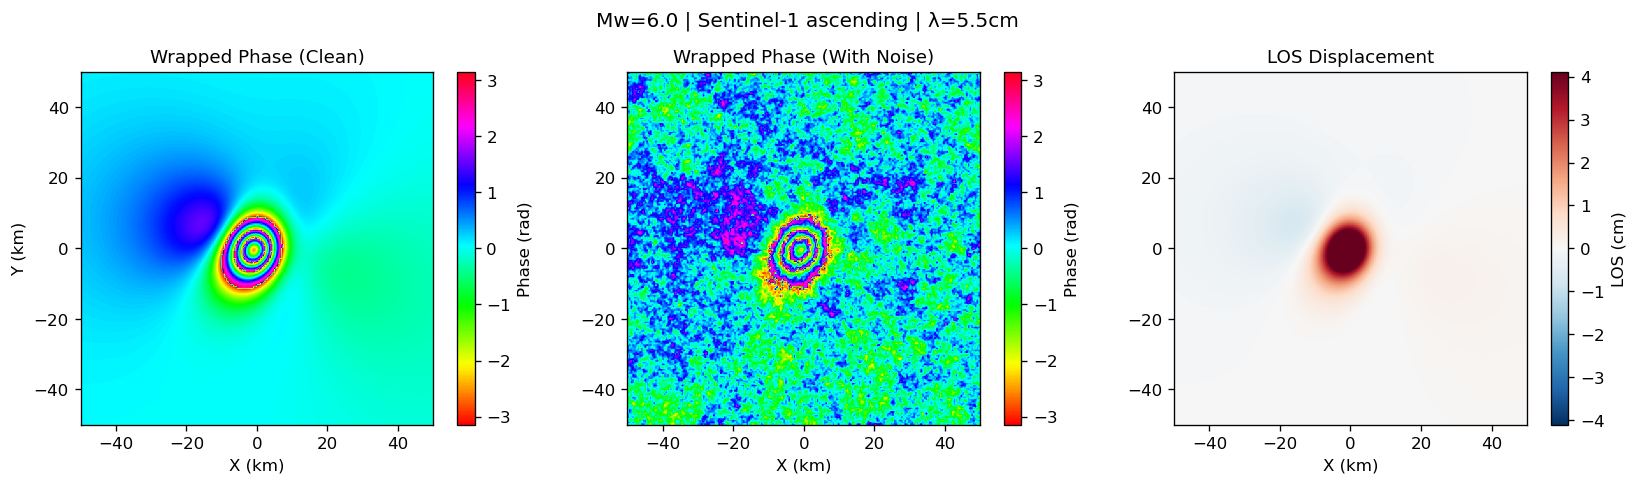

In [15]:
# Visualize InSAR products
fig = plot_insar_products(result, title_prefix="")
plt.tight_layout()
plt.show()

### Using the batch process

In [17]:
# Generate a small batch
batch = generate_training_batch(
    n_samples=12,
    mw_range=(5.0, 6.5),
    depth_range_km=(5, 20),
    satellite='sentinel1',
    n_pre=2,
    n_event=1,
    n_post=2,
    seed=42,
    verbose=False
)

print(f"Generated {len(batch)} samples")
print(f"\nSample parameters:")
for i, sample in enumerate(batch): #Want to see info on all
    meta = sample['metadata']
    print(f"  Sample {i}: Mw={meta['Mw']:.1f}, depth={meta['depth_km']:.1f} km, "
          f"strike={meta['strike_deg']:.0f}\u00b0, dip={meta['dip_deg']:.0f}\u00b0, rake={meta['rake_deg']:.0f}\u00b0")

Generated 12 samples

Sample parameters:
  Sample 0: Mw=5.6, depth=14.0 km, strike=56°, dip=47°, rake=-92°
  Sample 1: Mw=5.2, depth=8.6 km, strike=118°, dip=62°, rake=-88°
  Sample 2: Mw=6.3, depth=10.4 km, strike=129°, dip=51°, rake=-79°
  Sample 3: Mw=6.5, depth=6.2 km, strike=160°, dip=32°, rake=103°
  Sample 4: Mw=6.2, depth=16.4 km, strike=113°, dip=76°, rake=-12°
  Sample 5: Mw=5.2, depth=10.3 km, strike=255°, dip=29°, rake=78°
  Sample 6: Mw=5.0, depth=9.5 km, strike=285°, dip=81°, rake=13°
  Sample 7: Mw=5.5, depth=18.4 km, strike=246°, dip=46°, rake=-76°
  Sample 8: Mw=5.7, depth=10.9 km, strike=136°, dip=69°, rake=-72°
  Sample 9: Mw=6.0, depth=14.7 km, strike=102°, dip=33°, rake=110°
  Sample 10: Mw=6.2, depth=14.3 km, strike=35°, dip=57°, rake=-70°
  Sample 11: Mw=6.3, depth=10.3 km, strike=211°, dip=82°, rake=-8°


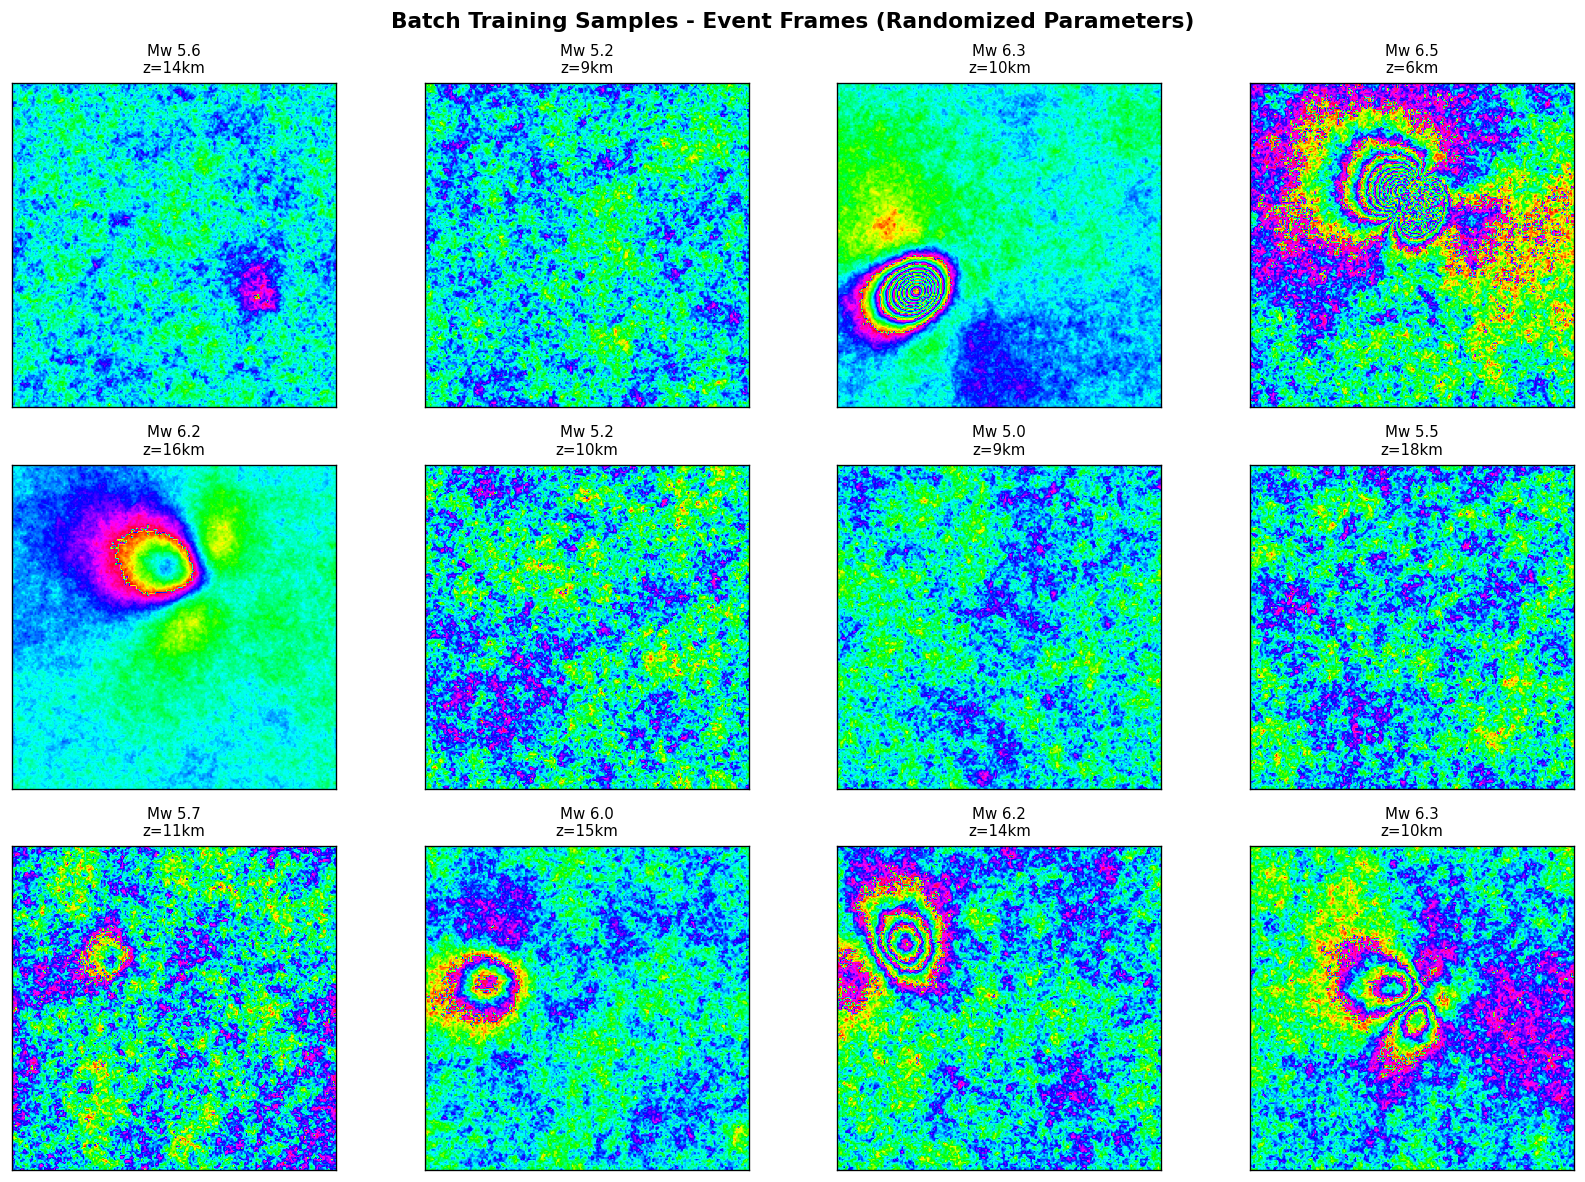

In [18]:
# Visualize batch samples (event frame only)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for idx, sample in enumerate(batch):
    ax = axes[idx // 4, idx % 4]
    
    # Get event frame (index 2 with n_pre=2)
    event_frame = sample['timeseries'][2]
    meta = sample['metadata']
    
    ax.imshow(event_frame, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f"Mw {meta['Mw']:.1f}\nz={meta['depth_km']:.0f}km", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Batch Training Samples - Event Frames (Randomized Parameters)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Looking at high-quality figure generation 

In [19]:
# Generate high-quality result
pub_result = generate_synthetic_insar(
    Mw=6.2,
    strike_deg=35,
    dip_deg=40,
    rake_deg=85,
    depth_km=12,
    grid_extent_km=60,
    grid_spacing_km=0.3,
    satellite='sentinel1',
    orbit='ascending',
    add_noise=True,
    noise_amplitude_m=0.003,  # 3 mm - subtle noise
    seed=123
)

C:\Users\ILiV4\AppData\Local\Temp\ipykernel_8812\2867713480.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


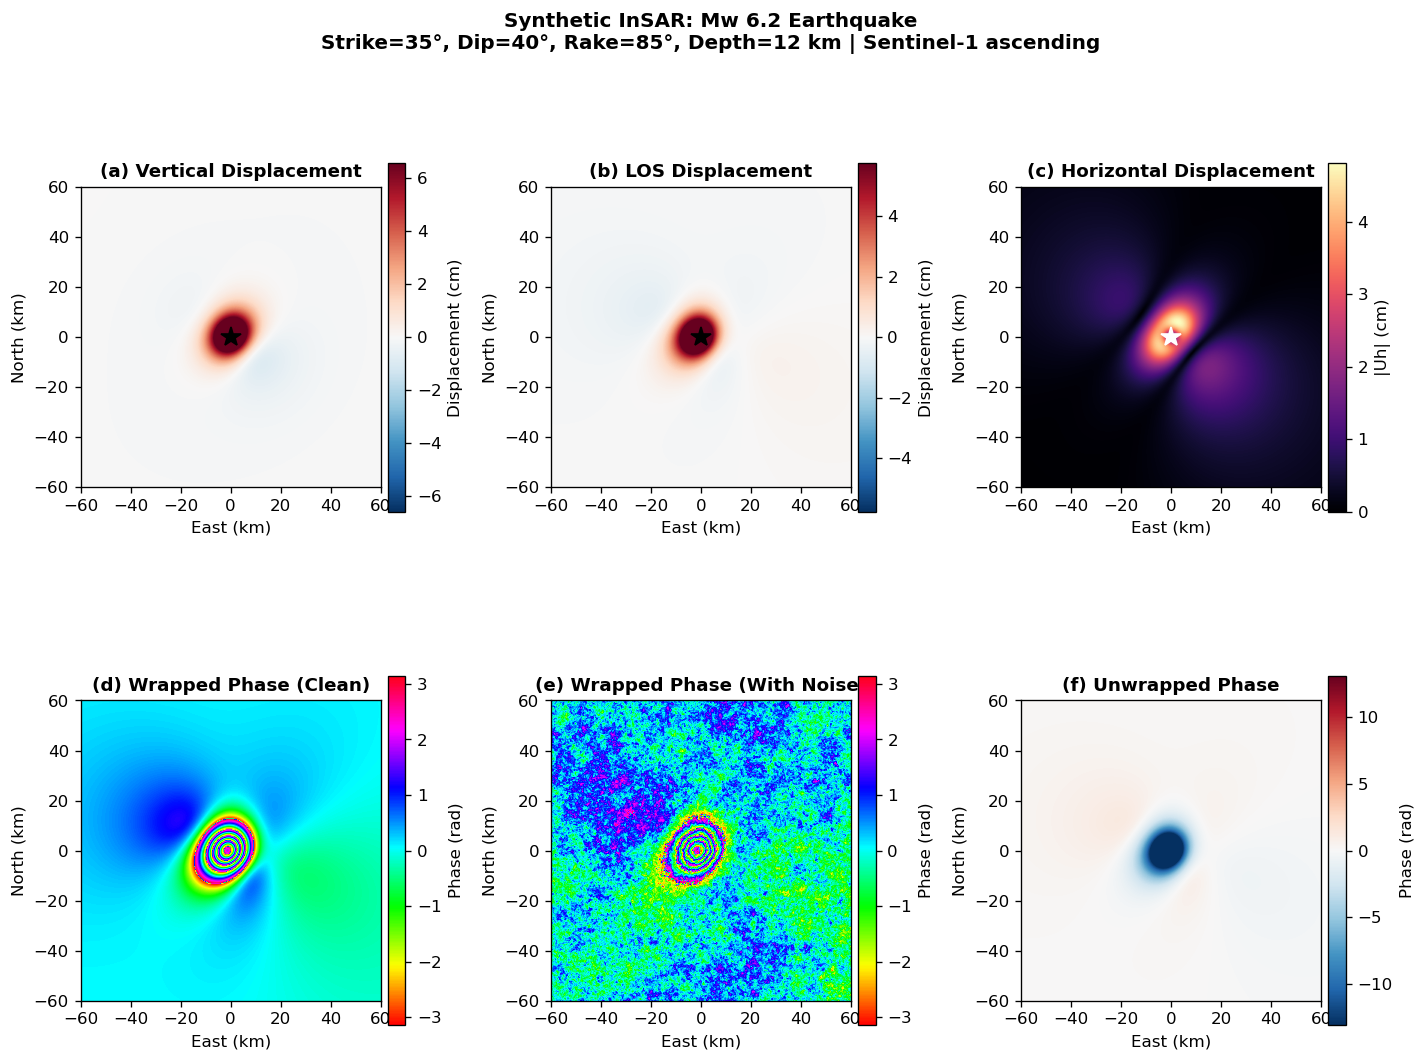


Figure saved as 'synthetic_insar_example.png'


In [20]:
# Create publication figure
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.25, wspace=0.3)

X = pub_result['X_km']
Y = pub_result['Y_km']
extent = [X.min(), X.max(), Y.min(), Y.max()]
meta = pub_result['metadata']

def add_colorbar(im, ax, label):
    cbar = plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label(label, fontsize=10)
    return cbar

# (a) Vertical displacement
ax1 = fig.add_subplot(gs[0, 0])
uz = pub_result['Uz'] * 100
vmax_uz = np.percentile(np.abs(uz), 99)
im1 = ax1.imshow(uz, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_uz, vmax=vmax_uz)
ax1.set_title('(a) Vertical Displacement', fontweight='bold')
ax1.set_xlabel('East (km)')
ax1.set_ylabel('North (km)')
ax1.plot(meta['xcen_km'], meta['ycen_km'], 'k*', markersize=12, label='Epicenter')
add_colorbar(im1, ax1, 'Displacement (cm)')

# (b) LOS displacement
ax2 = fig.add_subplot(gs[0, 1])
los = pub_result['los_displacement'] * 100
vmax_los = np.percentile(np.abs(los), 99)
im2 = ax2.imshow(los, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_los, vmax=vmax_los)
ax2.set_title('(b) LOS Displacement', fontweight='bold')
ax2.set_xlabel('East (km)')
ax2.set_ylabel('North (km)')
ax2.plot(meta['xcen_km'], meta['ycen_km'], 'k*', markersize=12)
add_colorbar(im2, ax2, 'Displacement (cm)')

# (c) Horizontal displacement magnitude
ax3 = fig.add_subplot(gs[0, 2])
uh = np.sqrt(pub_result['Ue']**2 + pub_result['Un']**2) * 100
im3 = ax3.imshow(uh, extent=extent, origin='lower', cmap='magma', vmin=0)
ax3.set_title('(c) Horizontal Displacement', fontweight='bold')
ax3.set_xlabel('East (km)')
ax3.set_ylabel('North (km)')
ax3.plot(meta['xcen_km'], meta['ycen_km'], 'w*', markersize=12)
add_colorbar(im3, ax3, '|Uh| (cm)')

# (d) Wrapped phase (clean)
ax4 = fig.add_subplot(gs[1, 0])
im4 = ax4.imshow(pub_result['phase_wrapped'], extent=extent, origin='lower', 
                  cmap='hsv', vmin=-np.pi, vmax=np.pi)
ax4.set_title('(d) Wrapped Phase (Clean)', fontweight='bold')
ax4.set_xlabel('East (km)')
ax4.set_ylabel('North (km)')
add_colorbar(im4, ax4, 'Phase (rad)')

# (e) Wrapped phase (noisy)
ax5 = fig.add_subplot(gs[1, 1])
im5 = ax5.imshow(pub_result['phase_noisy'], extent=extent, origin='lower',
                  cmap='hsv', vmin=-np.pi, vmax=np.pi)
ax5.set_title('(e) Wrapped Phase (With Noise)', fontweight='bold')
ax5.set_xlabel('East (km)')
ax5.set_ylabel('North (km)')
add_colorbar(im5, ax5, 'Phase (rad)')

# (f) Unwrapped phase
ax6 = fig.add_subplot(gs[1, 2])
unwrapped = pub_result['phase_unwrapped']
vmax_uw = np.percentile(np.abs(unwrapped), 99)
im6 = ax6.imshow(unwrapped, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_uw, vmax=vmax_uw)
ax6.set_title('(f) Unwrapped Phase', fontweight='bold')
ax6.set_xlabel('East (km)')
ax6.set_ylabel('North (km)')
add_colorbar(im6, ax6, 'Phase (rad)')

# Main title with earthquake parameters
title = (f"Synthetic InSAR: Mw {meta['Mw']:.1f} Earthquake\n"
         f"Strike={meta['strike_deg']:.0f}\u00b0, Dip={meta['dip_deg']:.0f}\u00b0, "
         f"Rake={meta['rake_deg']:.0f}\u00b0, Depth={meta['depth_km']:.0f} km | "
         f"{meta['satellite']} {meta['orbit']}")
fig.suptitle(title, fontsize=12, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('synthetic_insar_example.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("\nFigure saved as 'synthetic_insar_example.png'")

In [21]:
#Fancy indeed...

### More batch generations 

In [4]:
# Generate a small batch
batch = generate_training_batch(
    n_samples=12,
    mw_range=(1.0, 7.0),
    depth_range_km=(5, 50),
    satellite='sentinel1',
    n_pre=2,
    n_event=1,
    n_post=2,
    seed=54,
    verbose=False
)

print(f"Generated {len(batch)} samples")
print(f"\nSample parameters:")
for i, sample in enumerate(batch): #Want to see info on all
    meta = sample['metadata']
    print(f"  Sample {i}: Mw={meta['Mw']:.1f}, depth={meta['depth_km']:.1f} km, "
          f"strike={meta['strike_deg']:.0f}\u00b0, dip={meta['dip_deg']:.0f}\u00b0, rake={meta['rake_deg']:.0f}\u00b0")

Generated 12 samples

Sample parameters:
  Sample 0: Mw=3.5, depth=28.3 km, strike=3°, dip=23°, rake=87°
  Sample 1: Mw=1.6, depth=15.9 km, strike=191°, dip=45°, rake=62°
  Sample 2: Mw=6.9, depth=13.8 km, strike=128°, dip=51°, rake=-92°
  Sample 3: Mw=1.5, depth=19.0 km, strike=204°, dip=43°, rake=115°
  Sample 4: Mw=3.2, depth=8.4 km, strike=206°, dip=50°, rake=-69°
  Sample 5: Mw=6.5, depth=8.8 km, strike=206°, dip=79°, rake=16°
  Sample 6: Mw=2.8, depth=35.0 km, strike=204°, dip=34°, rake=116°
  Sample 7: Mw=5.9, depth=27.5 km, strike=347°, dip=47°, rake=98°
  Sample 8: Mw=1.2, depth=23.5 km, strike=227°, dip=52°, rake=-88°
  Sample 9: Mw=4.3, depth=28.7 km, strike=55°, dip=65°, rake=-75°
  Sample 10: Mw=3.3, depth=25.2 km, strike=165°, dip=80°, rake=28°
  Sample 11: Mw=2.3, depth=12.8 km, strike=109°, dip=37°, rake=67°


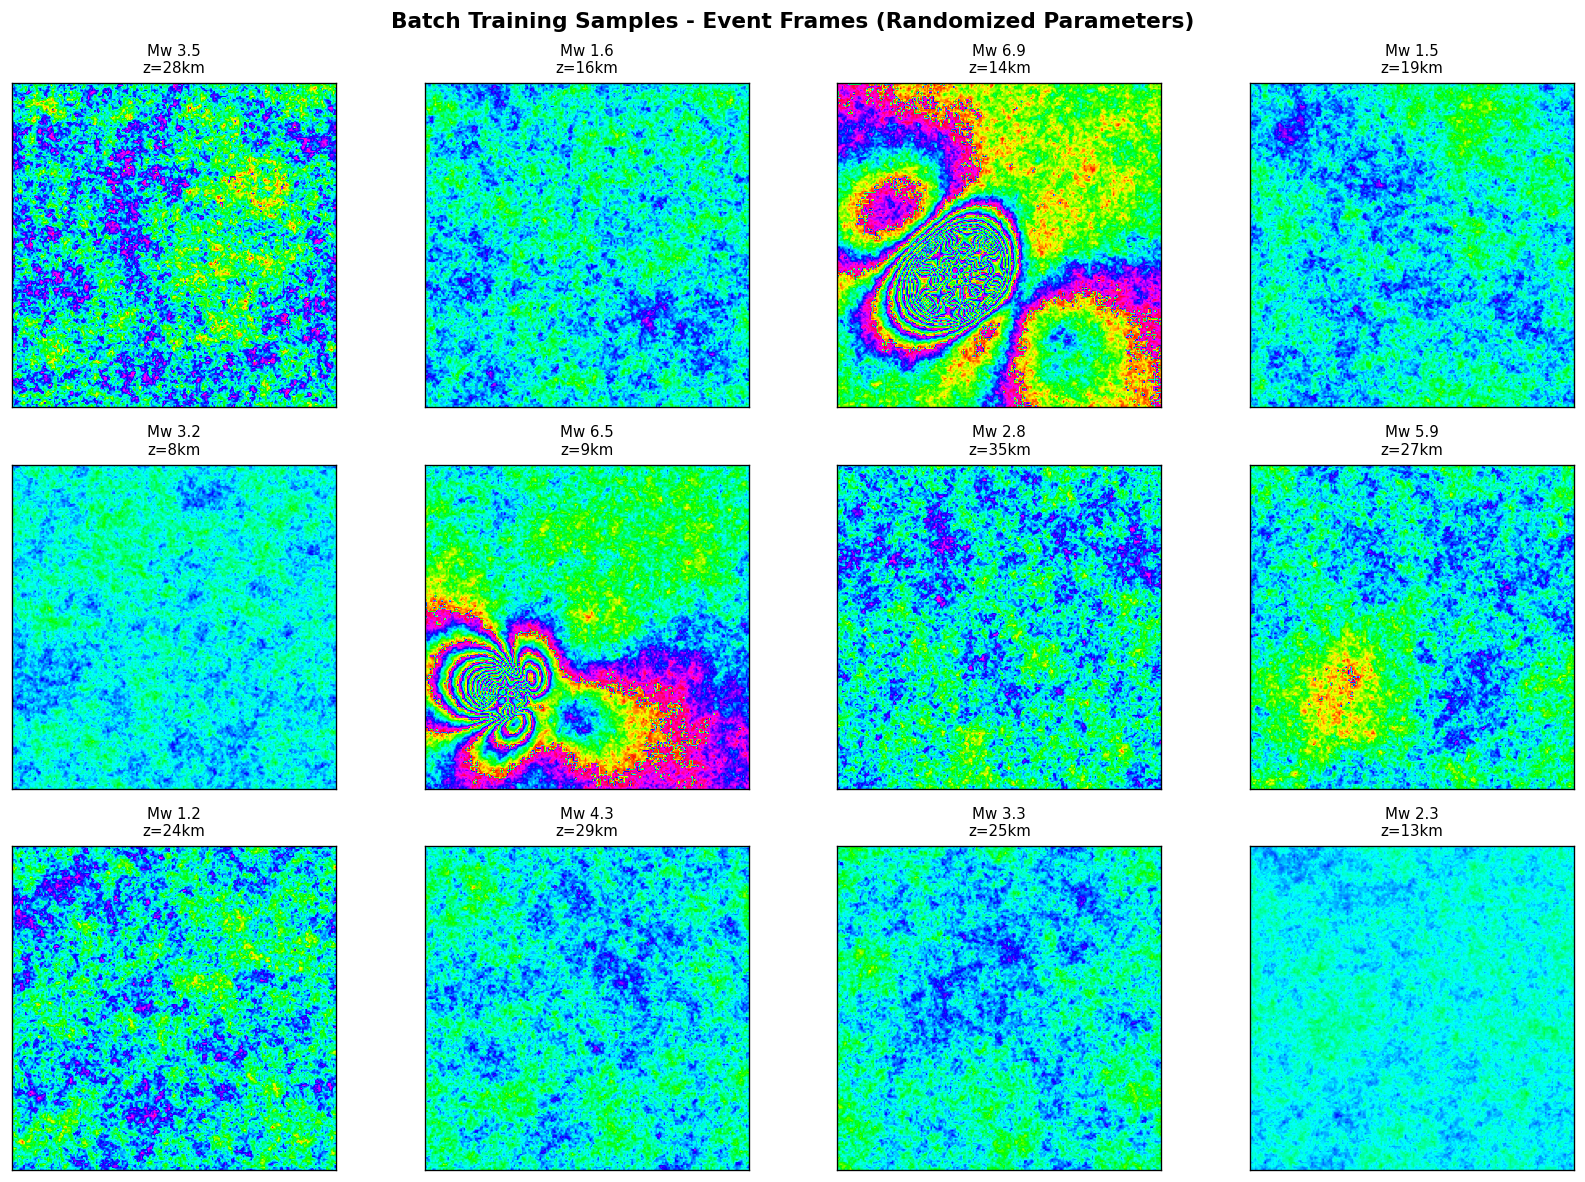

In [5]:
# Visualize batch samples (event frame only)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for idx, sample in enumerate(batch):
    ax = axes[idx // 4, idx % 4]
    
    # Get event frame (index 2 with n_pre=2)
    event_frame = sample['timeseries'][2]
    meta = sample['metadata']
    
    ax.imshow(event_frame, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f"Mw {meta['Mw']:.1f}\nz={meta['depth_km']:.0f}km", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Batch Training Samples - Event Frames (Randomized Parameters)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Testing the interferogram generation after adding decorrelation noise option

In [7]:
!py -m pytest eq-insar/tests/

============================= test session starts =============================
platform win32 -- Python 3.13.4, pytest-9.1.1, pluggy-1.6.0 -- C:\Users\ILiV4\AppData\Local\Programs\Python\Python313\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\ILiV4\research\repos\hbss\experiments\2026-09-MR-syn-interferogram-generator\eq-insar
configfile: pyproject.toml
plugins: cov-7.1.0
collecting ... collected 99 items

eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::test_output_keys_and_shapes PASSED [  1%]
eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::test_phase_bounded PASSED [  2%]
eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::test_zero_coherence_is_uniform PASSED [  3%]
eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::test_full_coherence_is_noise_free PASSED [  4%]
eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::test_more_looks_less_noise PASSED [  5%]
eq-insar\tests\test_decorrelation.py::TestDecorrelationNoise::t

In [8]:
# Now to generate some more interferograms, this time with decorrelation noise to see how they look. 

In [14]:
from eq_insar import generate_synthetic_insar, plot_insar_products
# Other important imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Get all the packages 
from eq_insar import (
    generate_synthetic_insar,
    generate_timeseries,
    generate_training_batch,
    list_satellites,
    get_satellite,
    plot_displacement_components,
    plot_insar_products,
    plot_timeseries_frames,
)

# Plot style
plt.style.use('default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

In [12]:
# Generate high-quality result
pub_result = generate_synthetic_insar(
    Mw=6.2,
    strike_deg=35,
    dip_deg=40,
    rake_deg=85,
    depth_km=12,
    grid_extent_km=60,
    grid_spacing_km=0.3,
    satellite='sentinel1',
    orbit='ascending',
    add_noise=True,
    noise_amplitude_m=0.003,  # 3 mm - subtle noise
    seed=123
)

C:\Users\ILiV4\AppData\Local\Temp\ipykernel_26940\1528219319.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


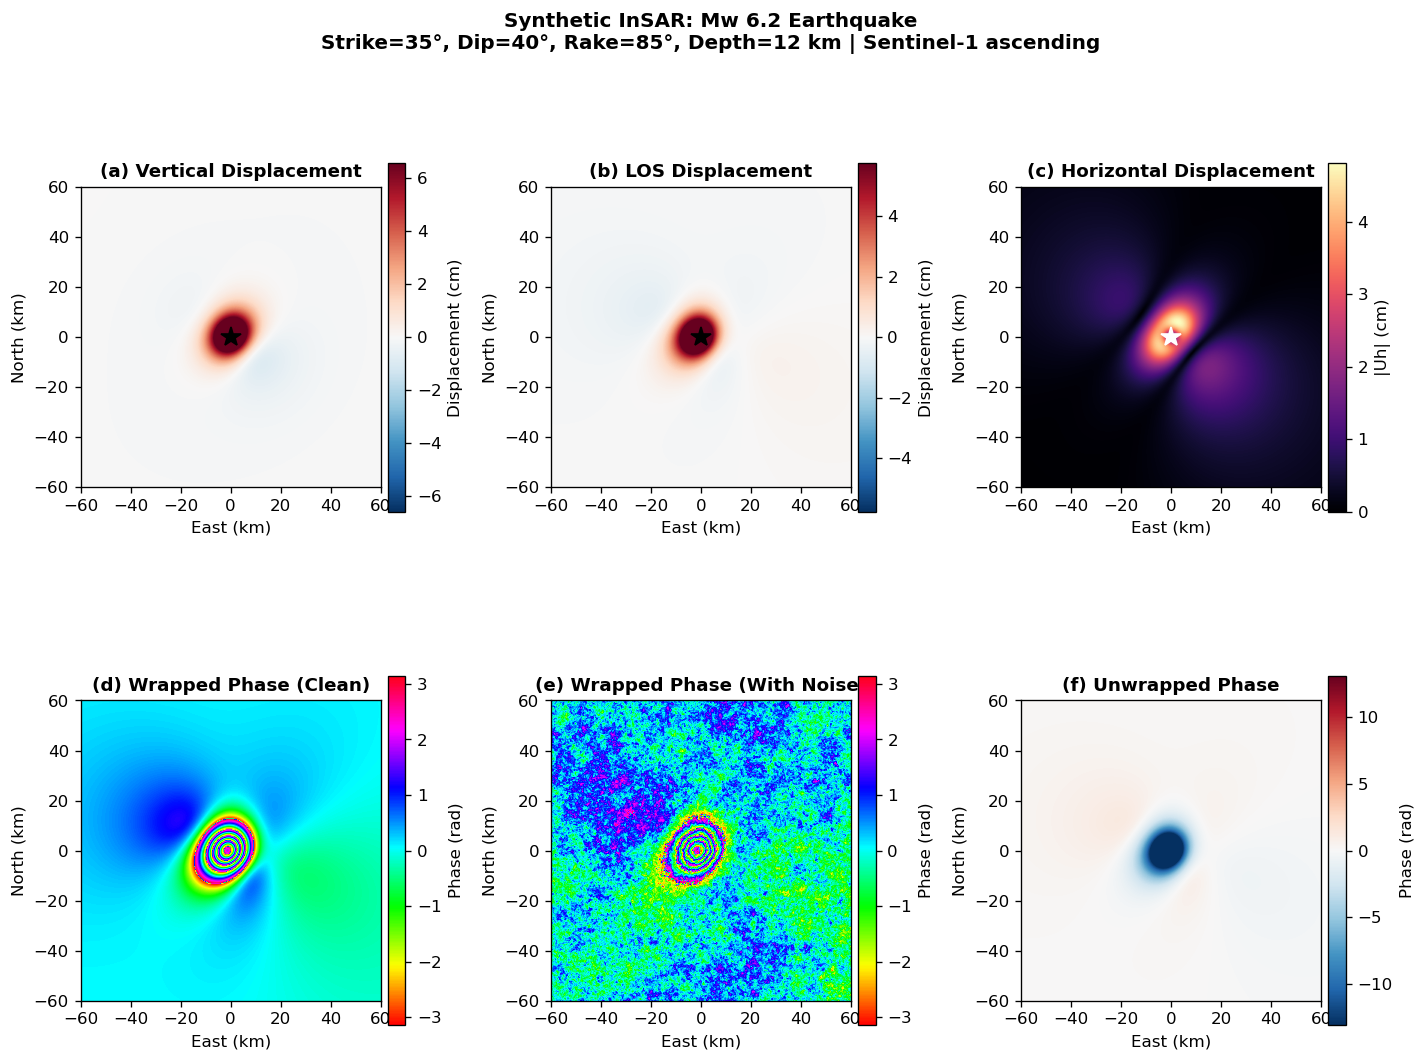


Figure saved as 'synthetic_insar_example2.png'


In [15]:
# Create publication figure
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.25, wspace=0.3)

X = pub_result['X_km']
Y = pub_result['Y_km']
extent = [X.min(), X.max(), Y.min(), Y.max()]
meta = pub_result['metadata']

def add_colorbar(im, ax, label):
    cbar = plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.set_label(label, fontsize=10)
    return cbar

# (a) Vertical displacement
ax1 = fig.add_subplot(gs[0, 0])
uz = pub_result['Uz'] * 100
vmax_uz = np.percentile(np.abs(uz), 99)
im1 = ax1.imshow(uz, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_uz, vmax=vmax_uz)
ax1.set_title('(a) Vertical Displacement', fontweight='bold')
ax1.set_xlabel('East (km)')
ax1.set_ylabel('North (km)')
ax1.plot(meta['xcen_km'], meta['ycen_km'], 'k*', markersize=12, label='Epicenter')
add_colorbar(im1, ax1, 'Displacement (cm)')

# (b) LOS displacement
ax2 = fig.add_subplot(gs[0, 1])
los = pub_result['los_displacement'] * 100
vmax_los = np.percentile(np.abs(los), 99)
im2 = ax2.imshow(los, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_los, vmax=vmax_los)
ax2.set_title('(b) LOS Displacement', fontweight='bold')
ax2.set_xlabel('East (km)')
ax2.set_ylabel('North (km)')
ax2.plot(meta['xcen_km'], meta['ycen_km'], 'k*', markersize=12)
add_colorbar(im2, ax2, 'Displacement (cm)')

# (c) Horizontal displacement magnitude
ax3 = fig.add_subplot(gs[0, 2])
uh = np.sqrt(pub_result['Ue']**2 + pub_result['Un']**2) * 100
im3 = ax3.imshow(uh, extent=extent, origin='lower', cmap='magma', vmin=0)
ax3.set_title('(c) Horizontal Displacement', fontweight='bold')
ax3.set_xlabel('East (km)')
ax3.set_ylabel('North (km)')
ax3.plot(meta['xcen_km'], meta['ycen_km'], 'w*', markersize=12)
add_colorbar(im3, ax3, '|Uh| (cm)')

# (d) Wrapped phase (clean)
ax4 = fig.add_subplot(gs[1, 0])
im4 = ax4.imshow(pub_result['phase_wrapped'], extent=extent, origin='lower', 
                  cmap='hsv', vmin=-np.pi, vmax=np.pi)
ax4.set_title('(d) Wrapped Phase (Clean)', fontweight='bold')
ax4.set_xlabel('East (km)')
ax4.set_ylabel('North (km)')
add_colorbar(im4, ax4, 'Phase (rad)')

# (e) Wrapped phase (noisy)
ax5 = fig.add_subplot(gs[1, 1])
im5 = ax5.imshow(pub_result['phase_noisy'], extent=extent, origin='lower',
                  cmap='hsv', vmin=-np.pi, vmax=np.pi)
ax5.set_title('(e) Wrapped Phase (With Noise)', fontweight='bold')
ax5.set_xlabel('East (km)')
ax5.set_ylabel('North (km)')
add_colorbar(im5, ax5, 'Phase (rad)')

# (f) Unwrapped phase
ax6 = fig.add_subplot(gs[1, 2])
unwrapped = pub_result['phase_unwrapped']
vmax_uw = np.percentile(np.abs(unwrapped), 99)
im6 = ax6.imshow(unwrapped, extent=extent, origin='lower', cmap='RdBu_r', vmin=-vmax_uw, vmax=vmax_uw)
ax6.set_title('(f) Unwrapped Phase', fontweight='bold')
ax6.set_xlabel('East (km)')
ax6.set_ylabel('North (km)')
add_colorbar(im6, ax6, 'Phase (rad)')

# Main title with earthquake parameters
title = (f"Synthetic InSAR: Mw {meta['Mw']:.1f} Earthquake\n"
         f"Strike={meta['strike_deg']:.0f}\u00b0, Dip={meta['dip_deg']:.0f}\u00b0, "
         f"Rake={meta['rake_deg']:.0f}\u00b0, Depth={meta['depth_km']:.0f} km | "
         f"{meta['satellite']} {meta['orbit']}")
fig.suptitle(title, fontsize=12, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('synthetic_insar_example2.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("\nFigure saved as 'synthetic_insar_example2.png'")

In [18]:
!python eq-insar/decorrelation_examples.py

Traceback (most recent call last):
  File "C:\Users\ILiV4\research\repos\hbss\experiments\2026-09-MR-syn-interferogram-generator\eq-insar\decorrelation_examples.py", line 83, in <module>
    results[name] = generate_synthetic_insar(
                    ^^^^^^^^^^^^^^^^^^^^^^^^^
TypeError: generate_synthetic_insar() got an unexpected keyword argument 'add_decorrelation'


In [4]:
import sys, subprocess
print(sys.executable)
!python -c "import sys, eq_insar; print(sys.executable); print(eq_insar.__file__)"

C:\Users\ILiV4\anaconda3\python.exe
C:\Users\ILiV4\anaconda3\python.exe
C:\Users\ILiV4\research\repos\hbss\experiments\2026-09-MR-syn-interferogram-generator\eq-insar\src\eq_insar\__init__.py


In [5]:
%pip install -e eq-insar

Obtaining file:///C:/Users/ILiV4/research/repos/hbss/experiments/2026-09-MR-syn-interferogram-generator/eq-insar
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for eq-insar (pyproject.toml): started
  Building editable for eq-insar (pyproject.toml): finished with status 'done'
  Created wheel for eq-insar: filename=eq_insar-0.2.0-0.editable-py3-none-any.whl size=6840 sha256=ccdab28d0bfda845d900f9b40d0837dd2de13aa7dfc508a9b78ae09dcda262d0
  Stored in directory: C:\Users\ILiV4\AppData\Local\Temp\pip-ephem-wheel-cache-um5zjzt4\w

In [6]:
import sys
!{sys.executable} eq-insar/decorrelation_examples.py

Saved decorrelation_examples.png and decorrelation_examples.npz


In [2]:
# Pictures saved in 2026-09-MR-syn-interferogram-generator

In [3]:
import sys
!{sys.executable} eq-insar/decorrelation_examples.py

Saved decorrelation_examples.png and decorrelation_examples.npz
